# 🚀 Модуль 5. Урок 1. Описательная статистика: среднее, медиана, мода, дисперсия и асимметрия

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_01_descriptive_stats_outliers.ipynb)

## 📌 Бизнес-контекст и методология
Среднее арифметическое в отчетах часто вводит бизнес в заблуждение. При асимметричных распределениях (доходы, чеки, MRR, время сессии) медиана и квантили показывают объективную реальность пользователя, а не влияние горстки гигантов.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    """Автоматически находит датасет локально или скачивает с GitHub репозитория курса."""
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    print(f"📥 Загрузка {filename} из репозитория курса...")
    urllib.request.urlretrieve(url, filename)
    print(f"✅ Датасет {filename} успешно готов!")
    return filename

# Загрузка датасетов
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Сравним среднее и медиану на данных SaaS пользователей, а также визуализируем форму распределения.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_saas = pd.read_csv(saas_csv)

mean_mrr = df_saas['mrr'].mean()
median_mrr = df_saas['mrr'].median()
std_mrr = df_saas['mrr'].std()
skew_mrr = df_saas['mrr'].skew()

print(f"Средний MRR:       ${mean_mrr:.2f}")
print(f"Медианный MRR:     ${median_mrr:.2f}")
print(f"Стандартное откл.: ${std_mrr:.2f}")
print(f"Коэф. асимметрии:  {skew_mrr:.2f} (скошен вправо)")

Средний MRR:       $79.00
Медианный MRR:     $29.00
Стандартное откл.: $82.02
Коэф. асимметрии:  1.92 (скошен вправо)


### 📊 Визуализация: почему среднее обманывает руководство
**Кейс:** Отдел продаж рапортует: «Средний чек клиента = $79». Инвесторы довольны, но финансовый директор видит кассовый разрыв.
Графики ниже наглядно объясняют, почему: 70% клиентов платят всего $29 (Starter), а среднее завышено горсткой корпоративных клиентов.

C:\Users\serge\AppData\Local\Temp\ipykernel_29596\3208495938.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(data_by_plan, labels=plans, patch_artist=True,


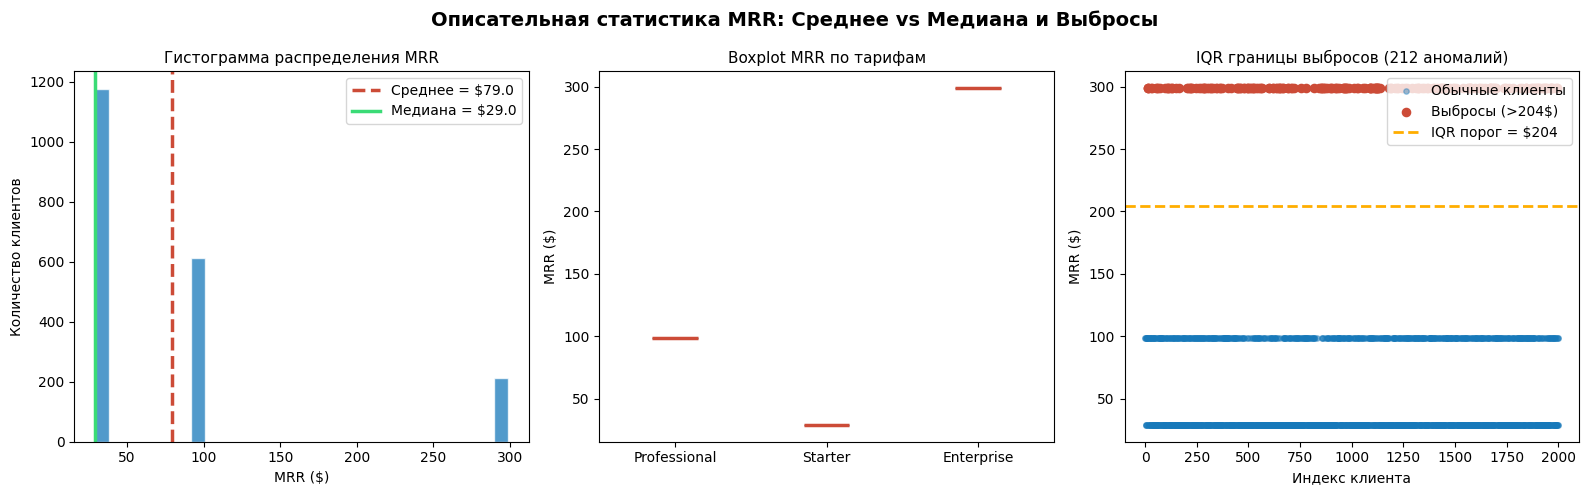

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Описательная статистика MRR: Среднее vs Медиана и Выбросы', fontsize=14, fontweight='bold')

# 1. Гистограмма с вертикальными метками среднего и медианы
ax1 = axes[0]
mrr = df_saas['mrr'].values
ax1.hist(mrr, bins=30, color='#1779ba', alpha=0.75, edgecolor='white')
ax1.axvline(mean_mrr, color='#cc4b37', linestyle='--', linewidth=2.5, label=f'Среднее = ${mean_mrr:.1f}')
ax1.axvline(median_mrr, color='#3adb76', linestyle='-', linewidth=2.5, label=f'Медиана = ${median_mrr:.1f}')
ax1.set_title('Гистограмма распределения MRR', fontsize=11)
ax1.set_xlabel('MRR ($)')
ax1.set_ylabel('Количество клиентов')
ax1.legend(loc='upper right')

# 2. Boxplot по тарифным планам
ax2 = axes[1]
plans = df_saas['plan'].unique()
data_by_plan = [df_saas[df_saas['plan']==p]['mrr'].values for p in plans]
bp = ax2.boxplot(data_by_plan, labels=plans, patch_artist=True,
                 boxprops=dict(facecolor='#1779ba', alpha=0.6),
                 medianprops=dict(color='#cc4b37', linewidth=2.5))
ax2.set_title('Boxplot MRR по тарифам', fontsize=11)
ax2.set_ylabel('MRR ($)')

# 3. Обнаружение выбросов: IQR метод
ax3 = axes[2]
q1, q3 = np.percentile(mrr, [25, 75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = max(0, q1 - 1.5 * iqr)
outliers = mrr[(mrr < lower_bound) | (mrr > upper_bound)]

ax3.scatter(range(len(mrr)), mrr, alpha=0.4, color='#1779ba', s=15, label='Обычные клиенты')
if len(outliers) > 0:
    outlier_idx = np.where((mrr < lower_bound) | (mrr > upper_bound))[0]
    ax3.scatter(outlier_idx, outliers, color='#cc4b37', s=35, label=f'Выбросы (>{upper_bound:.0f}$)')
ax3.axhline(upper_bound, color='#ffae00', linestyle='--', linewidth=2, label=f'IQR порог = ${upper_bound:.0f}')
ax3.set_title(f'IQR границы выбросов ({len(outliers)} аномалий)', fontsize=11)
ax3.set_xlabel('Индекс клиента')
ax3.set_ylabel('MRR ($)')
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Сравнение среднего и медианы по тарифным планам
Сгруппируйте `saas_users.csv` по тарифным планам (`plan`) и рассчитайте разницу между средним и медианой.

In [4]:
### ВАШ КОД ЗДЕСЬ
plan_stats = df_saas.groupby('plan')['mrr'].agg(['mean', 'median'])
plan_stats['diff'] = plan_stats['mean'] - plan_stats['median']

print(plan_stats)
assert not plan_stats.empty, "Сводка не должна быть пустой"
print("✅ Тест успешно пройден!")

               mean  median  diff
plan                             
Enterprise    299.0   299.0   0.0
Professional   99.0    99.0   0.0
Starter        29.0    29.0   0.0
✅ Тест успешно пройден!


### 💼 Когда использовать медиану?
Зарплаты, цены на недвижимость, чеки интернет-магазинов и время ответа сервера (latency p95/p99) всегда анализируются через медианы и квантили, так как они устойчивы к выбросам.